# Task 1 — E-Commerce Customer Churn Prediction System
**QSkill Internship · Slab 2 (Intermediate)**

**Goal:** understand why customers leave an e-commerce platform, build and compare classification models that predict churn, and turn the results into practical retention recommendations.

**Workflow**
1. Load & inspect data
2. Data cleaning
3. Exploratory data analysis (EDA)
4. Feature engineering
5. Train/test split & feature selection
6. Handling class imbalance
7. Building & comparing multiple models
8. Hyper-parameter tuning
9. Evaluation (precision, recall, F1, ROC-AUC, confusion matrices)
10. Important churn factors
11. Risk segmentation & business recommendations

> **Dataset note:** the notebook reads `../data/ecommerce_churn.csv`, which follows the column schema of the public Kaggle *E-Commerce Customer Churn* dataset. To use the real file, save it in `data/` as `ecommerce_churn.csv` (or use `pd.read_excel("../data/E Commerce Dataset.xlsx", sheet_name="E Comm")`) — no other code change is needed.

## 1. Setup & data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
RS = 42   # random state for reproducibility

In [2]:
df = pd.read_csv("../data/ecommerce_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,0,10.0,Mobile Phone,1,34.0,Debit Card,Female,3.0,4,Fashion,3,Single,6,0,19.0,0.0,3.0,4.0,195.71
1,50002,0,15.0,Mobile Phone,1,6.0,CC,Female,2.0,4,Laptop & Accessory,3,Single,5,0,12.0,1.0,3.0,3.0,170.98
2,50003,1,8.0,Mobile Phone,1,24.0,Credit Card,Female,2.0,5,Fashion,4,Married,5,1,18.0,3.0,4.0,4.0,168.15
3,50004,0,7.0,Mobile Phone,1,15.0,Cash on Delivery,Male,2.0,4,Laptop & Accessory,5,Divorced,2,0,18.0,0.0,4.0,3.0,173.25
4,50005,0,16.0,Phone,1,8.0,Debit Card,Male,2.0,4,Fashion,5,Married,2,0,26.0,1.0,3.0,1.0,157.24


## 2. Data understanding & cleaning

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5367 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5369 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5402 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.2500,52815.50,54222.7500,55630.0
Churn,5630.0,0.169272,0.375025,0.0,0.0000,0.00,0.0000,1.0
Tenure,5367.0,9.913546,9.422951,0.0,3.0000,7.00,14.0000,61.0
CityTier,5630.0,1.677442,0.925377,1.0,1.0000,1.00,3.0000,3.0
WarehouseToHome,5369.0,20.488173,10.182294,5.0,12.0000,20.00,28.0000,127.0
HourSpendOnApp,5402.0,2.525731,0.830911,0.0,2.0000,3.00,3.0000,5.0
NumberOfDeviceRegistered,5630.0,3.611368,1.033948,1.0,3.0000,4.00,4.0000,6.0
SatisfactionScore,5630.0,3.222202,1.447919,1.0,2.0000,3.00,5.0000,5.0
NumberOfAddress,5630.0,3.228774,1.507802,1.0,2.0000,3.00,4.0000,11.0
Complain,5630.0,0.279396,0.448742,0.0,0.0000,0.00,1.0000,1.0


### 2.1 Duplicates, missing values and inconsistent labels
Real customer data usually has the same category written in several ways (e.g. *Phone* vs *Mobile Phone*) and gaps in numeric columns. We check for both.

In [5]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())

missing = df.isna().sum()
missing = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

Duplicate rows       : 0
Duplicate CustomerIDs: 0


,missing,percent
Tenure,263,4.67
WarehouseToHome,261,4.64
OrderCount,253,4.49
DaySinceLastOrder,238,4.23
OrderAmountHikeFromlastYear,234,4.16
CouponUsed,231,4.10
HourSpendOnApp,228,4.05


In [6]:
categorical_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender", "PreferedOrderCat", "MaritalStatus"]
for c in categorical_cols:
    print(c, "->", sorted(df[c].unique()))

PreferredLoginDevice -> ['Computer', 'Mobile Phone', 'Phone']
PreferredPaymentMode -> ['CC', 'COD', 'Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
Gender -> ['Female', 'Male']
PreferedOrderCat -> ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile', 'Mobile Phone', 'Others']
MaritalStatus -> ['Divorced', 'Married', 'Single']


In [7]:
# Merge labels that mean the same thing
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({"CC": "Credit Card", "COD": "Cash on Delivery"})
df["PreferedOrderCat"] = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

for c in categorical_cols:
    print(c, "->", sorted(df[c].unique()))

PreferredLoginDevice -> ['Computer', 'Mobile Phone']
PreferredPaymentMode -> ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
Gender -> ['Female', 'Male']
PreferedOrderCat -> ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
MaritalStatus -> ['Divorced', 'Married', 'Single']


### 2.2 Outliers
`WarehouseToHome` (distance from warehouse to home) is checked with the IQR rule. Values that are physically implausible are set to missing and imputed later, inside the modelling pipeline (so that no information from the test set leaks into training).

IQR upper fence for WarehouseToHome: 52.0
Rows with WarehouseToHome > 60: 9


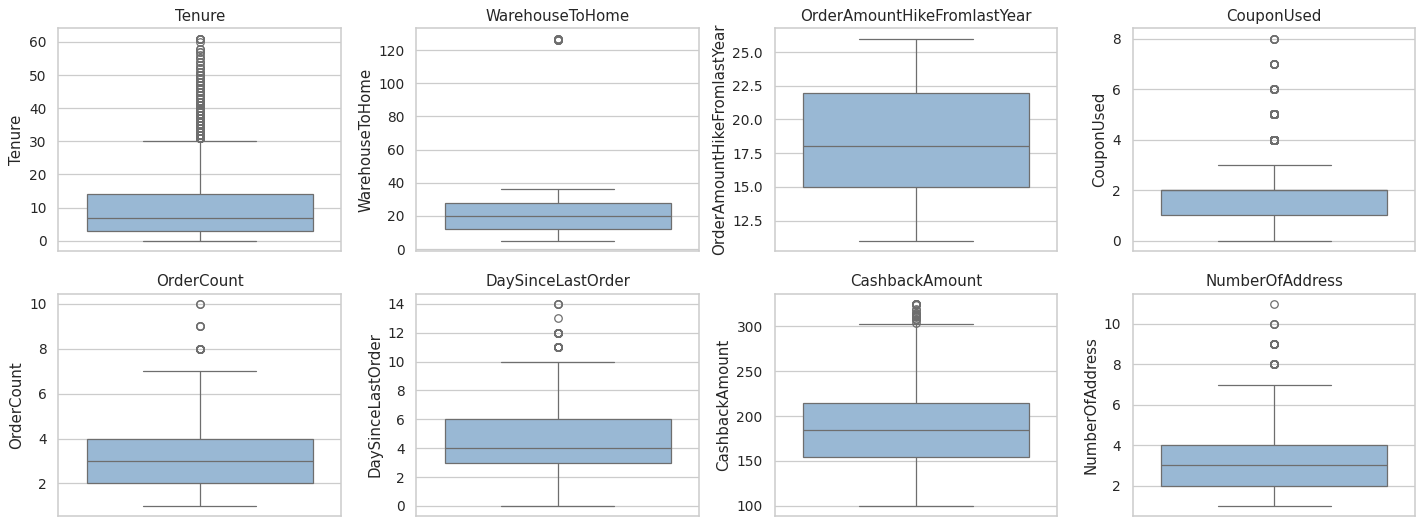

In [8]:
num_check = ["Tenure", "WarehouseToHome", "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount", "NumberOfAddress"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_check):
    sns.boxplot(y=df[c], ax=ax, color="#8fb8de")
    ax.set_title(c)
plt.tight_layout()
plt.show()

q1, q3 = df["WarehouseToHome"].quantile([0.25, 0.75])
print("IQR upper fence for WarehouseToHome:", q3 + 1.5 * (q3 - q1))
print("Rows with WarehouseToHome > 60:", (df["WarehouseToHome"] > 60).sum())

In [9]:
df.loc[df["WarehouseToHome"] > 60, "WarehouseToHome"] = np.nan   # implausible distance -> treat as missing
df = df.drop(columns=["CustomerID"])                             # identifier, no predictive value
print("Remaining missing values per column:")
df.isna().sum()[df.isna().sum() > 0]

Remaining missing values per column:


Tenure                         263
WarehouseToHome                270
HourSpendOnApp                 228
OrderAmountHikeFromlastYear    234
CouponUsed                     231
OrderCount                     253
DaySinceLastOrder              238
dtype: int64

**Cleaning decisions**
- Merged duplicate category labels (`Phone`/`Mobile Phone`, `CC`/`Credit Card`, `COD`/`Cash on Delivery`, `Mobile`/`Mobile Phone`).
- Removed the ID column and treated implausible warehouse distances as missing.
- Missing numeric values are filled with the **median** and missing categories with the **mode**, but this is done inside a `Pipeline` that is fitted on training data only.

## 3. Exploratory data analysis

### 3.1 How many customers churn?

Churn
Stayed     4677
Churned     953
Name: count, dtype: int64

Churn rate: 16.93%


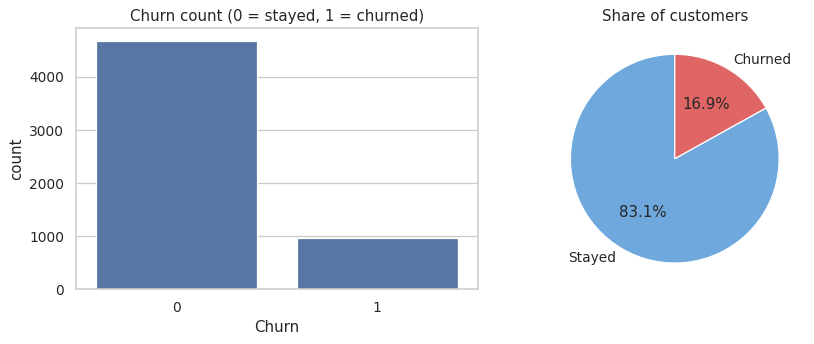

In [10]:
churn_counts = df["Churn"].value_counts().rename({0: "Stayed", 1: "Churned"})
print(churn_counts)
print("\nChurn rate: %.2f%%" % (df["Churn"].mean() * 100))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Churn", data=df, ax=ax[0])
ax[0].set_title("Churn count (0 = stayed, 1 = churned)")
ax[1].pie(churn_counts, labels=churn_counts.index, autopct="%1.1f%%", colors=["#6fa8dc", "#e06666"], startangle=90)
ax[1].set_title("Share of customers")
plt.tight_layout()
plt.show()

The target is **imbalanced** (roughly 1 churner for every 5 loyal customers). Accuracy alone would be misleading, so precision, recall, F1 and ROC-AUC are used and imbalance is handled explicitly in Section 6.

### 3.2 Churn rate across customer groups

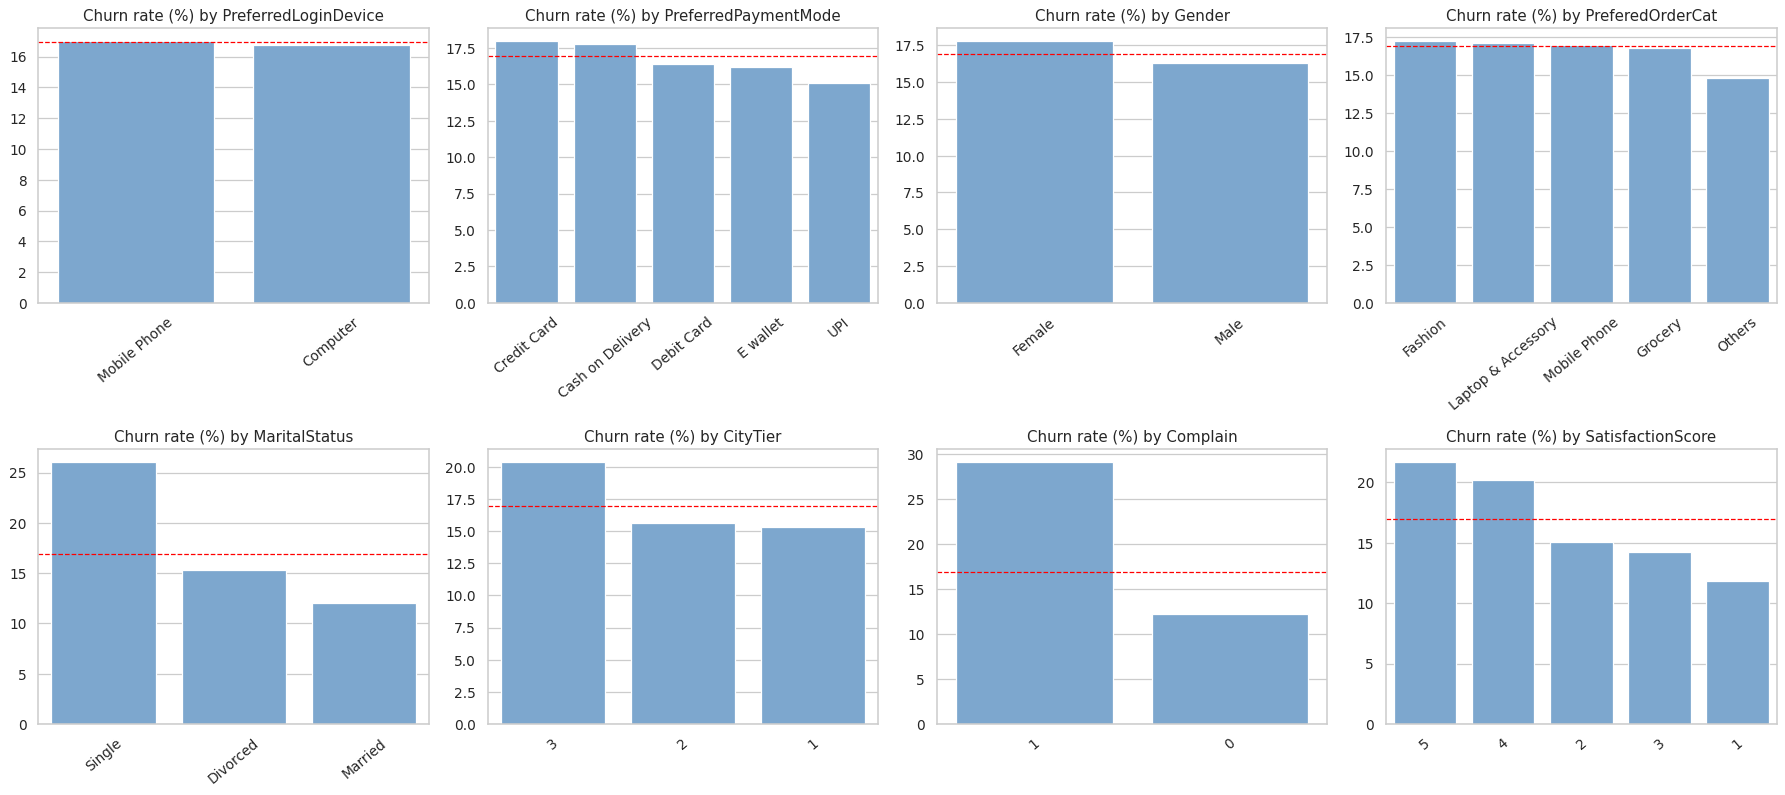

In [11]:
cat_eda = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender", "PreferedOrderCat",
           "MaritalStatus", "CityTier", "Complain", "SatisfactionScore"]
overall = df["Churn"].mean() * 100
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), cat_eda):
    rate = df.groupby(c)["Churn"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#6fa8dc")
    ax.axhline(overall, color="red", ls="--", lw=1)
    ax.set_title("Churn rate (%) by " + c)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

In [12]:
# Highest-risk segment inside each categorical feature
rows = []
for c in cat_eda:
    r = df.groupby(c)["Churn"].agg(["mean", "size"])
    top = r["mean"].idxmax()
    rows.append({"feature": c, "highest-churn group": top, "churn rate %": round(r.loc[top, "mean"] * 100, 1),
                 "customers": int(r.loc[top, "size"])})
pd.DataFrame(rows).sort_values("churn rate %", ascending=False).reset_index(drop=True)

,feature,highest-churn group,churn rate %,customers
0,Complain,1,29.1,1573
1,MaritalStatus,Single,26.0,1776
2,SatisfactionScore,5,21.6,1497
3,CityTier,3,20.3,1795
4,PreferredPaymentMode,Credit Card,18.0,1621
5,Gender,Female,17.8,2352
6,PreferedOrderCat,Fashion,17.2,813
7,PreferredLoginDevice,Mobile Phone,17.0,3983


### 3.3 Numeric behaviour: churned vs retained customers

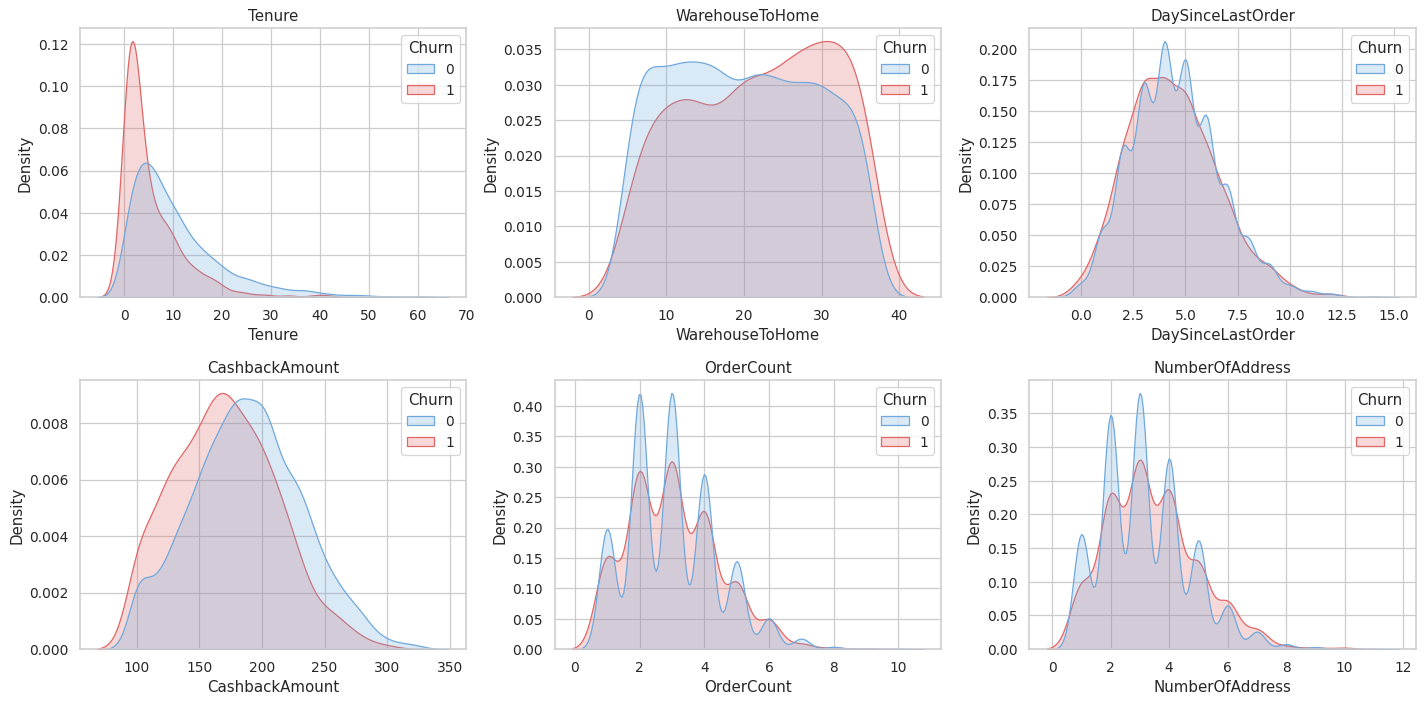

In [13]:
num_eda = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount", "OrderCount", "NumberOfAddress"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_eda):
    sns.kdeplot(data=df, x=c, hue="Churn", common_norm=False, fill=True, ax=ax, palette=["#6fa8dc", "#e06666"])
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [14]:
df.groupby("Churn")[["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount", "OrderCount",
                     "NumberOfAddress", "NumberOfDeviceRegistered", "CouponUsed"]].mean().round(2).T

Churn,0,1
Tenure,10.82,5.48
WarehouseToHome,19.98,21.96
DaySinceLastOrder,4.53,4.39
CashbackAmount,187.90,170.45
OrderCount,3.01,3.04
NumberOfAddress,3.19,3.41
NumberOfDeviceRegistered,3.59,3.73
CouponUsed,1.69,1.81


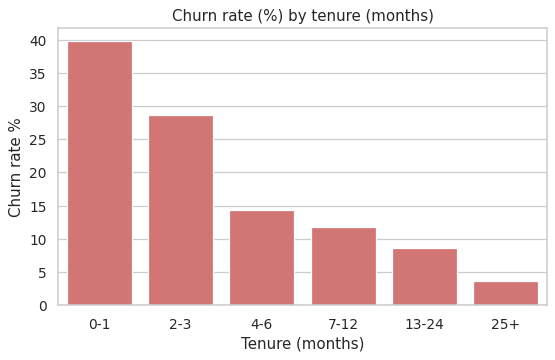

In [15]:
tenure_bins = pd.cut(df["Tenure"], bins=[-1, 1, 3, 6, 12, 24, 62], labels=["0-1", "2-3", "4-6", "7-12", "13-24", "25+"])
rate = df.groupby(tenure_bins, observed=True)["Churn"].mean().mul(100)
plt.figure(figsize=(7, 4))
sns.barplot(x=rate.index.astype(str), y=rate.values, color="#e06666")
plt.title("Churn rate (%) by tenure (months)")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn rate %")
plt.show()

### 3.4 Correlations

Tenure                        -0.213
Complain                       0.201
CashbackAmount                -0.149
SatisfactionScore              0.098
WarehouseToHome                0.080
CityTier                       0.061
NumberOfAddress                0.055
NumberOfDeviceRegistered       0.053
CouponUsed                     0.032
OrderAmountHikeFromlastYear    0.027
DaySinceLastOrder             -0.026
HourSpendOnApp                 0.015
OrderCount                     0.010
Name: Churn, dtype: float64

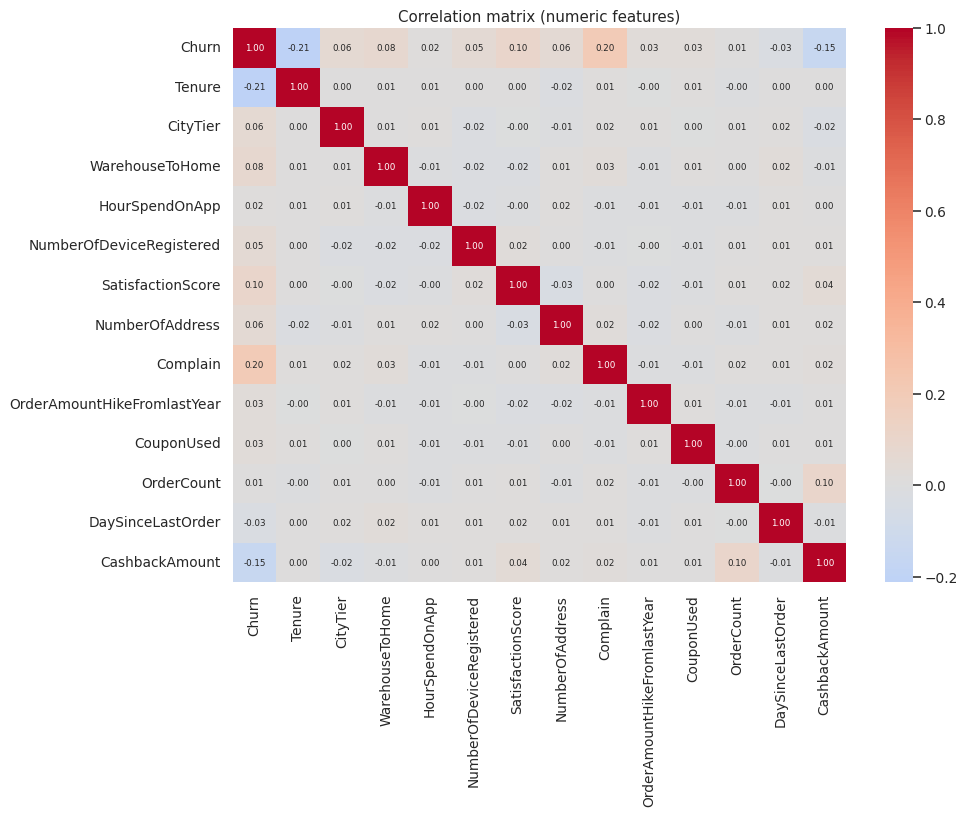

In [16]:
plt.figure(figsize=(11, 8))
corr = df.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix (numeric features)")
plt.show()

corr["Churn"].drop("Churn").sort_values(key=abs, ascending=False).round(3)

## 4. Feature engineering
New columns that describe *behaviour* rather than raw counts. They only use values from the same row, so creating them before the train/test split cannot leak information.

| New feature | Idea |
|---|---|
| `is_new_customer` | joined within the last 3 months — highest churn window |
| `orders_per_month` | order frequency relative to tenure |
| `cashback_per_order` | reward received per order |
| `coupon_per_order` | dependence on discounts |
| `devices_per_address` | account-sharing / multi-device behaviour |
| `low_satisfaction` | satisfaction score of 1 or 2 |
| `far_from_warehouse` | long delivery distance (> 20 km) |
| `complaint_new_customer` | complained **and** is new — double risk signal |

In [17]:
d = df.copy()
d["is_new_customer"] = (d["Tenure"] <= 3).astype(int)
d["orders_per_month"] = d["OrderCount"] / (d["Tenure"] + 1)
d["cashback_per_order"] = d["CashbackAmount"] / d["OrderCount"]
d["coupon_per_order"] = d["CouponUsed"] / d["OrderCount"]
d["devices_per_address"] = d["NumberOfDeviceRegistered"] / d["NumberOfAddress"]
d["low_satisfaction"] = (d["SatisfactionScore"] <= 2).astype(int)
d["far_from_warehouse"] = (d["WarehouseToHome"] > 20).astype(int)
d["complaint_new_customer"] = ((d["Complain"] == 1) & (d["is_new_customer"] == 1)).astype(int)
d = d.replace([np.inf, -np.inf], np.nan)

new_feats = ["is_new_customer", "orders_per_month", "cashback_per_order", "coupon_per_order",
             "devices_per_address", "low_satisfaction", "far_from_warehouse", "complaint_new_customer"]
d[new_feats + ["Churn"]].corr()["Churn"].drop("Churn").round(3).sort_values(key=abs, ascending=False)

complaint_new_customer    0.268
is_new_customer           0.264
orders_per_month          0.233
low_satisfaction         -0.070
far_from_warehouse        0.061
cashback_per_order       -0.056
coupon_per_order          0.025
devices_per_address      -0.023
Name: Churn, dtype: float64

## 5. Train / test split and feature selection
The split is **stratified** so both sets keep the same churn rate. Feature selection is performed on the **training set only**.

In [18]:
X = d.drop(columns="Churn")
y = d["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("Train:", X_train.shape, " churn rate = %.3f" % y_train.mean())
print("Test :", X_test.shape, " churn rate = %.3f" % y_test.mean())

Train: (4504, 26)  churn rate = 0.169
Test : (1126, 26)  churn rate = 0.170


**Selection method:** (1) mutual information between each feature and churn, and (2) removal of one feature from any pair that is almost perfectly correlated (|r| > 0.85).

orders_per_month               0.0364
Tenure                         0.0359
complaint_new_customer         0.0327
is_new_customer                0.0279
MaritalStatus                  0.0125
Complain                       0.0121
WarehouseToHome                0.0108
CashbackAmount                 0.0083
CityTier                       0.0057
SatisfactionScore              0.0053
NumberOfAddress                0.0038
cashback_per_order             0.0012
devices_per_address            0.0007
OrderCount                     0.0006
PreferredPaymentMode           0.0004
NumberOfDeviceRegistered       0.0003
far_from_warehouse             0.0003
PreferedOrderCat               0.0003
Gender                         0.0002
PreferredLoginDevice           0.0001
HourSpendOnApp                 0.0000
OrderAmountHikeFromlastYear    0.0000
DaySinceLastOrder              0.0000
CouponUsed                     0.0000
coupon_per_order               0.0000
low_satisfaction               0.0000
dtype: float

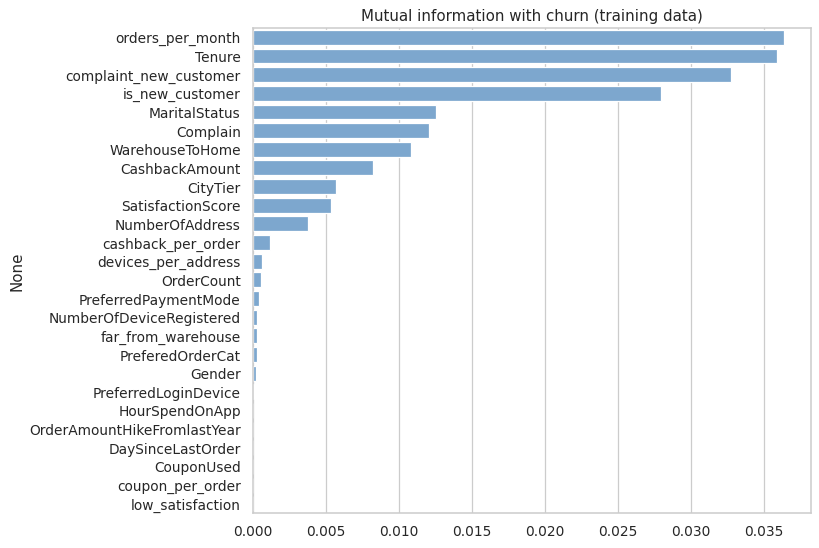

In [19]:
cat_cols_all = [c for c in categorical_cols if c in X_train.columns]
num_cols_all = [c for c in X_train.columns if c not in cat_cols_all]

# Quick numeric encoding just for mutual information
tmp = X_train.copy()
tmp[num_cols_all] = tmp[num_cols_all].fillna(tmp[num_cols_all].median())
for c in cat_cols_all:
    tmp[c] = tmp[c].astype("category").cat.codes
mi = mutual_info_classif(tmp, y_train, discrete_features=[c in cat_cols_all for c in tmp.columns], random_state=RS)
mi = pd.Series(mi, index=tmp.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(x=mi.values, y=mi.index, color="#6fa8dc")
plt.title("Mutual information with churn (training data)")
plt.show()
mi.round(4)

In [20]:
MI_THRESHOLD = 0.003
corr_tr = X_train[num_cols_all].corr().abs()
upper = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if any(upper[c] > 0.85)]
drop_low_mi = list(mi[mi < MI_THRESHOLD].index)

print("Dropped (highly correlated)  :", drop_corr)
print("Dropped (low mutual info)    :", drop_low_mi)

selected = [c for c in X_train.columns if c not in set(drop_corr) | set(drop_low_mi)]
cat_cols = [c for c in selected if c in cat_cols_all]
num_cols = [c for c in selected if c not in cat_cols_all]
print("\nSelected %d of %d features" % (len(selected), X_train.shape[1]))
print("Categorical:", cat_cols)
print("Numerical  :", num_cols)

Dropped (highly correlated)  : ['low_satisfaction', 'far_from_warehouse']
Dropped (low mutual info)    : ['cashback_per_order', 'devices_per_address', 'OrderCount', 'PreferredPaymentMode', 'NumberOfDeviceRegistered', 'far_from_warehouse', 'PreferedOrderCat', 'Gender', 'PreferredLoginDevice', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'DaySinceLastOrder', 'CouponUsed', 'coupon_per_order', 'low_satisfaction']

Selected 11 of 26 features
Categorical: ['MaritalStatus']
Numerical  : ['Tenure', 'CityTier', 'WarehouseToHome', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'CashbackAmount', 'is_new_customer', 'orders_per_month', 'complaint_new_customer']


## 6. Handling class imbalance
Four strategies are compared with the same Random Forest using **5-fold stratified cross-validation on the training data**. Re-sampling is applied *inside each training fold only*, never to the validation fold.

| Strategy | What it does |
|---|---|
| None | train on the data as is |
| Class weights | penalise mistakes on the churn class more |
| Random oversampling | duplicate churners until classes are balanced |
| Random undersampling | drop loyal customers until classes are balanced |

In [21]:
def make_preprocessor(num_cols, cat_cols, scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

Xtr = X_train[selected].reset_index(drop=True)
ytr = y_train.reset_index(drop=True)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

def resample_fold(Xf, yf, how, seed=RS):
    rng = np.random.RandomState(seed)
    pos, neg = np.where(yf == 1)[0], np.where(yf == 0)[0]
    if how == "oversample":
        idx = np.concatenate([neg, pos, rng.choice(pos, len(neg) - len(pos), replace=True)])
    elif how == "undersample":
        idx = np.concatenate([pos, rng.choice(neg, len(pos), replace=False)])
    else:
        idx = np.arange(len(yf))
    return Xf.iloc[idx], yf.iloc[idx]

results = []
for name, how, cw in [("None", None, None), ("Class weights", None, "balanced"),
                      ("Random oversampling", "oversample", None), ("Random undersampling", "undersample", None)]:
    scores = {"precision": [], "recall": [], "f1": [], "roc_auc": []}
    for tr, va in skf.split(Xtr, ytr):
        Xf, yf = resample_fold(Xtr.iloc[tr], ytr.iloc[tr], how)
        pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols)),
                         ("model", RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=5, class_weight=cw, random_state=RS, n_jobs=-1))])
        pipe.fit(Xf, yf)
        proba = pipe.predict_proba(Xtr.iloc[va])[:, 1]
        pred = (proba >= 0.5).astype(int)
        scores["precision"].append(precision_score(ytr.iloc[va], pred, zero_division=0))
        scores["recall"].append(recall_score(ytr.iloc[va], pred))
        scores["f1"].append(f1_score(ytr.iloc[va], pred))
        scores["roc_auc"].append(roc_auc_score(ytr.iloc[va], proba))
    results.append({"strategy": name, **{k: np.mean(v) for k, v in scores.items()}})

imb_table = pd.DataFrame(results).set_index("strategy").round(3)
imb_table

,precision,recall,f1,roc_auc
strategy,,,,
None,0.615,0.218,0.320,0.809
Class weights,0.440,0.572,0.497,0.808
Random oversampling,0.418,0.605,0.494,0.807
Random undersampling,0.358,0.738,0.482,0.806


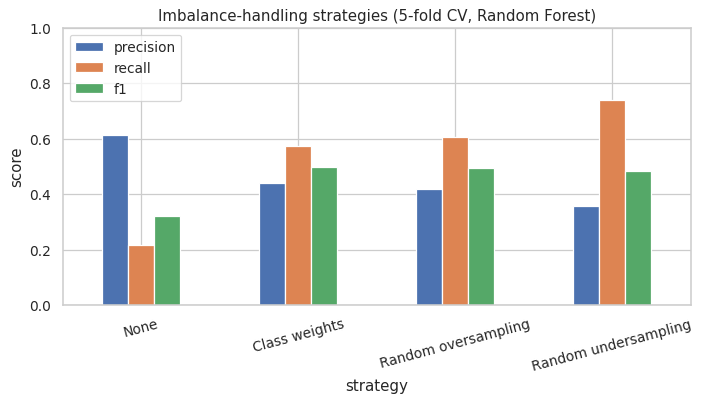

In [22]:
imb_table[["precision", "recall", "f1"]].plot(kind="bar", figsize=(9, 4), rot=15)
plt.title("Imbalance-handling strategies (5-fold CV, Random Forest)")
plt.ylabel("score")
plt.ylim(0, 1)
plt.show()

**Decision:** plain training favours the majority class (low recall). Class weighting lifts recall without duplicating or discarding any rows, and — unlike manual re-sampling — plugs directly into cross-validation and hyper-parameter search. All models below therefore use `class_weight="balanced"`.

*(Optional extension: SMOTE from the `imbalanced-learn` package can be tested the same way.)*

## 7. Building and comparing multiple models
Five classifiers, each inside a pipeline (impute → encode → scale where needed → model), evaluated with 5-fold stratified CV on the training data.

In [23]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), True),
    "Decision Tree":       (DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, class_weight="balanced", random_state=RS), False),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, class_weight="balanced", random_state=RS, n_jobs=-1), False),
    "Extra Trees":         (ExtraTreesClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5, class_weight="balanced", random_state=RS, n_jobs=-1), False),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RS), False),
}
scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for name, (est, scale) in models.items():
    pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols, scale=scale)), ("model", est)])
    cv = cross_validate(pipe, Xtr, ytr, cv=skf, scoring=scoring)
    rows.append({"model": name, **{m: cv["test_" + m].mean() for m in scoring}})

cv_table = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False).round(3)
cv_table

,precision,recall,f1,roc_auc
model,,,,
Random Forest,0.439,0.572,0.496,0.808
Extra Trees,0.385,0.684,0.493,0.805
Logistic Regression,0.361,0.738,0.485,0.818
Hist Gradient Boosting,0.410,0.570,0.476,0.795
Decision Tree,0.340,0.695,0.456,0.768


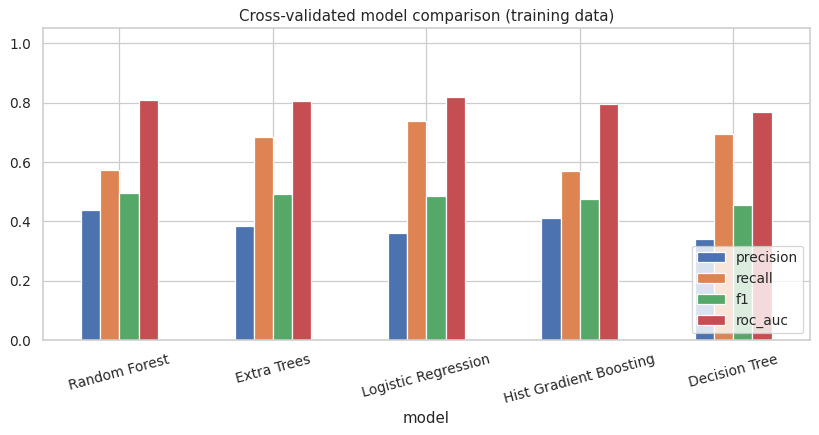

In [24]:
cv_table.plot(kind="bar", figsize=(11, 4.5), rot=15)
plt.title("Cross-validated model comparison (training data)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

## 8. Hyper-parameter tuning
The two best models from the cross-validated comparison (by F1) are tuned with `RandomizedSearchCV` (3-fold, optimising **F1** because it balances precision and recall on an imbalanced target).

In [25]:
best_models = cv_table.index[:2].tolist()
print("Top 2 models selected for tuning:", best_models)

search_space = {
    "Random Forest": {"model__n_estimators": [200, 300], "model__max_depth": [None, 8, 12, 16],
                      "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 2, 4],
                      "model__max_features": ["sqrt", 0.5]},
    "Extra Trees": {"model__n_estimators": [200, 300], "model__max_depth": [None, 8, 12, 16],
                    "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 2, 4],
                    "model__max_features": ["sqrt", 0.5]},
    "Hist Gradient Boosting": {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [None, 4, 6, 8],
                               "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [10, 20, 40],
                               "model__l2_regularization": [0, 0.1, 1.0]},
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"model__max_depth": [3, 4, 6, 8, 12], "model__min_samples_leaf": [5, 10, 20, 40]},
}

tuned = {}
for name in best_models:
    est, scale = models[name]
    pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols, scale=scale)), ("model", est)])
    rs = RandomizedSearchCV(pipe, search_space[name], n_iter=10, scoring="f1",
                            cv=StratifiedKFold(3, shuffle=True, random_state=RS), random_state=RS, n_jobs=1)
    rs.fit(Xtr, ytr)
    tuned[name] = rs.best_estimator_
    print("%-24s best CV F1 = %.3f" % (name, rs.best_score_))
    print("   ", {k.replace("model__", ""): v for k, v in rs.best_params_.items()})

Top 2 models selected for tuning: ['Random Forest', 'Extra Trees']
Random Forest            best CV F1 = 0.509
    {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 8}
Extra Trees              best CV F1 = 0.497
    {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 12}


## 9. Final evaluation on the untouched test set
Baseline (untuned Logistic Regression) and the tuned models are scored on data that was never used for selection or tuning.

In [26]:
X_te = X_test[selected]
baseline = Pipeline([("prep", make_preprocessor(num_cols, cat_cols, scale=True)), ("model", models["Logistic Regression"][0])]).fit(Xtr, ytr)
final_models = {"Baseline: Logistic Regression": baseline}
final_models.update({"Tuned " + k: v for k, v in tuned.items()})

rows, probas = [], {}
for name, m in final_models.items():
    p = m.predict_proba(X_te)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows.append({"model": name, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, p)})
test_table = pd.DataFrame(rows).set_index("model").round(3)
test_table

,precision,recall,f1,roc_auc
model,,,,
Baseline: Logistic Regression,0.393,0.749,0.515,0.815
Tuned Random Forest,0.410,0.571,0.477,0.789
Tuned Extra Trees,0.411,0.628,0.497,0.792


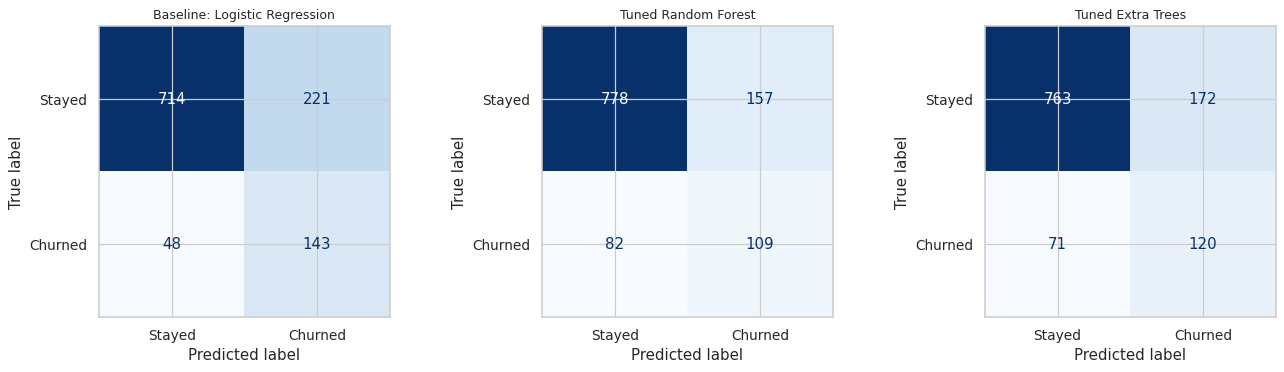

In [27]:
fig, axes = plt.subplots(1, len(final_models), figsize=(5 * len(final_models), 4.3))
for ax, (name, p) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= 0.5).astype(int), display_labels=["Stayed", "Churned"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

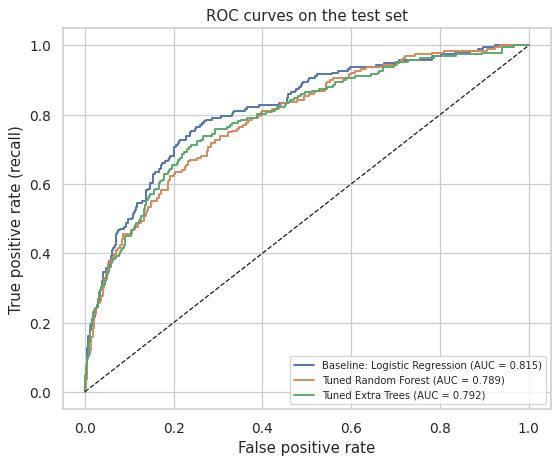

In [28]:
plt.figure(figsize=(7, 5.5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label="%s (AUC = %.3f)" % (name, roc_auc_score(y_test, p)))
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right", fontsize=8)
plt.show()

### 9.1 Choosing the best model and a decision threshold
Note that the simple Logistic Regression baseline is very competitive with the tuned tree ensembles — a sign that most of the churn signal is captured by a handful of fairly linear relationships (complaints, tenure, marital status, cashback). Simple, explainable models are a perfectly good production choice here.

The best tuned model (by test F1) is selected. The default 0.5 threshold is not necessarily optimal for an imbalanced problem, so the threshold is chosen using **cross-validated predictions on the training data only** and then applied once to the test set.

In [29]:
best_name = test_table.drop(index="Baseline: Logistic Regression")["f1"].idxmax()
best_model = final_models[best_name]
print("Best model:", best_name)

oof = cross_val_predict(best_model, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(ytr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = thr[np.argmax(f1s)]
print("Threshold maximising F1 on training folds: %.3f" % best_thr)

p_best = probas[best_name]
for label, t in [("default 0.5", 0.5), ("tuned %.2f" % best_thr, best_thr)]:
    pred = (p_best >= t).astype(int)
    print("%-12s precision=%.3f  recall=%.3f  F1=%.3f" % (label, precision_score(y_test, pred),
                                                             recall_score(y_test, pred), f1_score(y_test, pred)))
print()
print(classification_report(y_test, (p_best >= best_thr).astype(int), target_names=["Stayed", "Churned"]))

Best model: Tuned Extra Trees
Threshold maximising F1 on training folds: 0.533
default 0.5  precision=0.411  recall=0.628  F1=0.497
tuned 0.53   precision=0.430  recall=0.576  F1=0.492

              precision    recall  f1-score   support

      Stayed       0.91      0.84      0.87       935
     Churned       0.43      0.58      0.49       191

    accuracy                           0.80      1126
   macro avg       0.67      0.71      0.68      1126
weighted avg       0.83      0.80      0.81      1126



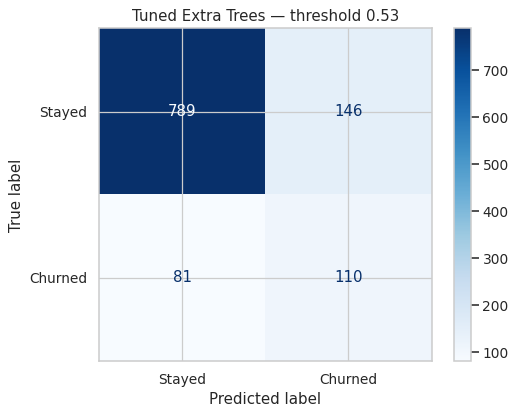

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test, (p_best >= best_thr).astype(int), display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("%s — threshold %.2f" % (best_name, best_thr))
plt.show()

## 10. Most important churn factors
**Permutation importance** on the test set: each feature is shuffled in turn and the drop in ROC-AUC shows how much the model relies on it. Unlike built-in tree importances, it is not biased towards high-cardinality features.

,feature,importance,std
0,MaritalStatus,0.0387,0.0089
1,Complain,0.0382,0.0063
2,is_new_customer,0.0313,0.0067
3,SatisfactionScore,0.0239,0.0070
4,Tenure,0.0235,0.0047
5,CashbackAmount,0.0181,0.0029
6,complaint_new_customer,0.0101,0.0014
7,CityTier,0.0034,0.0035
8,WarehouseToHome,0.0020,0.0035
9,NumberOfAddress,0.0009,0.0025


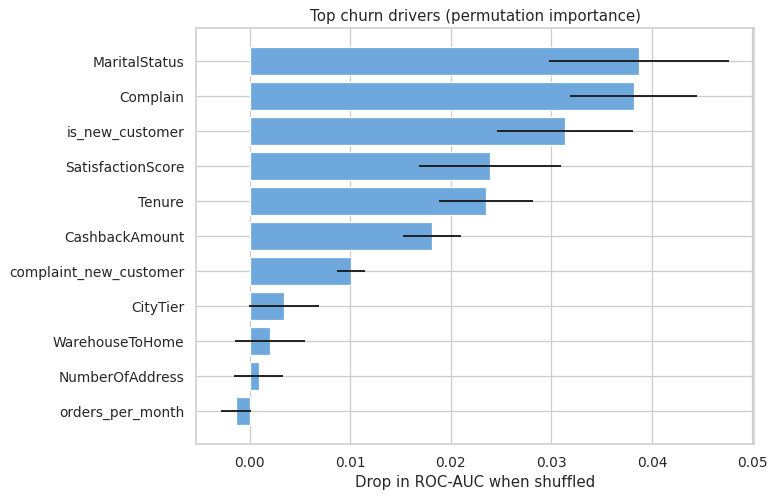

In [31]:
pi = permutation_importance(best_model, X_te, y_test, scoring="roc_auc", n_repeats=10, random_state=RS, n_jobs=1)
imp = pd.DataFrame({"feature": X_te.columns, "importance": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 6))
top = imp.head(12).iloc[::-1]
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#6fa8dc")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Top churn drivers (permutation importance)")
plt.show()
imp.head(12).round(4)

In [32]:
# Effect sizes of the main drivers on the full cleaned data
print("Overall churn rate: %.1f%%\n" % (d["Churn"].mean() * 100))
checks = {
    "Customers who complained":         d["Complain"] == 1,
    "Customers who never complained":   d["Complain"] == 0,
    "New customers (tenure <= 3 months)": d["is_new_customer"] == 1,
    "Established customers (tenure > 12)": d["Tenure"] > 12,
    "Low satisfaction (score 1-2)":     d["low_satisfaction"] == 1,
    "Single customers":                 d["MaritalStatus"] == "Single",
    "City tier 3":                      d["CityTier"] == 3,
    "5+ addresses on file":             d["NumberOfAddress"] >= 5,
    "Complained AND new":               d["complaint_new_customer"] == 1,
}
pd.DataFrame({k: {"customers": int(v.sum()), "churn rate %": round(d.loc[v, "Churn"].mean() * 100, 1)}
              for k, v in checks.items()}).T

Overall churn rate: 16.9%



,customers,churn rate %
Customers who complained,1573.0,29.1
Customers who never complained,4057.0,12.2
New customers (tenure <= 3 months),1463.0,33.6
Established customers (tenure > 12),1487.0,7.2
Low satisfaction (score 1-2),1687.0,12.9
Single customers,1776.0,26.0
City tier 3,1795.0,20.3
5+ addresses on file,1061.0,19.6
Complained AND new,415.0,52.5


In [33]:
# Satisfaction score and cashback level vs churn
print("Churn rate (%) by satisfaction score:")
print(d.groupby("SatisfactionScore")["Churn"].mean().mul(100).round(1).to_string())
print("\nChurn rate (%) by cashback quartile:")
print(d.groupby(pd.qcut(d["CashbackAmount"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]), observed=True)["Churn"].mean().mul(100).round(1).to_string())

Churn rate (%) by satisfaction score:
SatisfactionScore
1    11.8
2    15.0
3    14.2
4    20.2
5    21.6

Churn rate (%) by cashback quartile:
CashbackAmount
Q1 (lowest)     24.3
Q2              18.7
Q3              14.9
Q4 (highest)     9.8


## 11. Risk segmentation
Predicted probabilities are converted into risk tiers so the retention team can prioritise who to contact first.

In [34]:
seg = pd.DataFrame({"prob": p_best, "churn": y_test.values})
seg["risk_tier"] = pd.cut(seg["prob"], bins=[-0.01, 0.30, 0.60, 1.0], labels=["Low (<0.30)", "Medium (0.30-0.60)", "High (>0.60)"])
tier = seg.groupby("risk_tier", observed=True).agg(customers=("churn", "size"), actual_churners=("churn", "sum"),
                                                   actual_churn_rate=("churn", "mean"))
tier["share_of_all_churners_%"] = (tier["actual_churners"] / seg["churn"].sum() * 100).round(1)
tier["actual_churn_rate"] = (tier["actual_churn_rate"] * 100).round(1)
tier

,customers,actual_churners,actual_churn_rate,share_of_all_churners_%
risk_tier,,,,
Low (<0.30),561,34,6.1,17.8
Medium (0.30-0.60),363,64,17.6,33.5
High (>0.60),202,93,46.0,48.7


Contacting the top 10% highest-risk customers reaches 34% of all churners
Contacting the top 20% highest-risk customers reaches 53% of all churners
Contacting the top 30% highest-risk customers reaches 69% of all churners


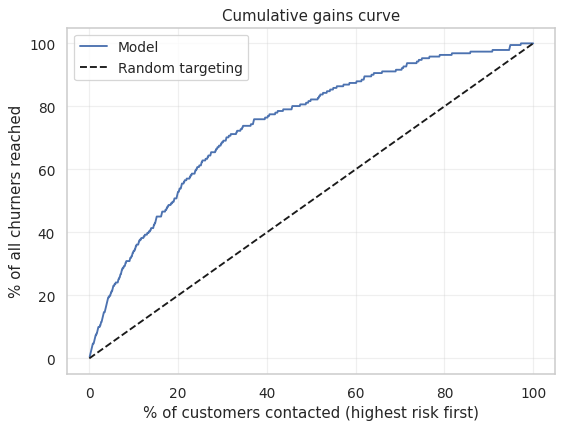

In [35]:
# Lift: how many churners do we catch by contacting only the top-scored customers?
seg_sorted = seg.sort_values("prob", ascending=False).reset_index(drop=True)
seg_sorted["cum_churners_%"] = seg_sorted["churn"].cumsum() / seg_sorted["churn"].sum() * 100
seg_sorted["contacted_%"] = (seg_sorted.index + 1) / len(seg_sorted) * 100
plt.figure(figsize=(7, 5))
plt.plot(seg_sorted["contacted_%"], seg_sorted["cum_churners_%"], label="Model")
plt.plot([0, 100], [0, 100], "k--", label="Random targeting")
plt.xlabel("% of customers contacted (highest risk first)")
plt.ylabel("% of all churners reached")
plt.title("Cumulative gains curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
for pct in (10, 20, 30):
    row = seg_sorted.iloc[int(len(seg_sorted) * pct / 100) - 1]
    print("Contacting the top %d%% highest-risk customers reaches %.0f%% of all churners" % (pct, row["cum_churners_%"]))

## 12. Practical recommendations for reducing churn
Based on the EDA, the churn drivers in Section 10 and the effect sizes above:

1. **Treat complaints as a churn alarm.** Customers who complained churn at a much higher rate than those who never did. Introduce a service-recovery workflow: resolve within 24–48 hours, follow up proactively, and offer a goodwill gesture (coupon / cashback) after resolution.
2. **Win the first 90 days.** Churn is concentrated in customers with very short tenure. Build an onboarding journey — welcome offer, first-repeat-purchase incentive, and delivery-experience check-ins in months 1–3.
3. **Do not trust the satisfaction score on its own.** The table above shows churn does *not* fall as satisfaction rises — highly-rated customers still leave. Add an exit/“why did you leave” survey and track price, competitor and delivery reasons, rather than assuming a high score means a safe customer.
4. **Pay attention to segment and reward level.** Single customers and customers receiving lower cashback churn more; test segment-specific offers (e.g. student/young-professional bundles) and a minimum cashback/loyalty benefit for at-risk accounts. City-tier-3 customers also churn above average, so check delivery speed and payment options there.
5. **Use the model as a daily watch-list.** Score the base weekly, send the **High-risk tier** to the retention team first (see the gains curve — a small share of customers contains a large share of future churners), and run A/B tests on the offers.
6. **Keep loyal customers engaged.** Reward repeat orders (loyalty points, early access) rather than relying only on coupons; track tenure, cashback received and complaint history as early-warning signals.
7. **Monitor and retrain.** Re-train quarterly and monitor precision/recall drift; adjust the decision threshold to the cost of a retention offer versus the value of a retained customer.

## 13. Summary
- Cleaned inconsistent labels, outliers and missing values (imputation inside the pipeline to avoid leakage).
- Explored behaviour with EDA and engineered 8 behavioural features.
- Selected features with mutual information and correlation filtering on the training set only.
- Compared four imbalance strategies and five classifiers with stratified cross-validation, then tuned the top two.
- Evaluated with precision, recall, F1, ROC-AUC, confusion matrices and a cross-validated decision threshold.
- Identified key churn factors with permutation importance and converted predictions into risk tiers and recommendations.